<a href="https://colab.research.google.com/github/hossain8078/Machine-Learning-and-Deep-Learning/blob/main/Lab_3_Iris_Hyperparameter_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Exercise 3: Hyperparameter Tuning for Classification

##Md Alamgir Hossain, Business Information Systems (BIS), Saskatchewan Polytechnic

### Step 1: Import Libraries

In this step, we will import all the necessary libraries for data manipulation, modeling, and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All required Libraries imported successfully.")

Libraries imported successfully.


**Section note.** All packages used for loading data, tuning, evaluation, and the heatmap are imported here.

### Step 2: Load and Prepare the Data

Load the Iris dataset and split it into training and testing sets. Stratification ensures that the proportion of classes is the same in both the training and test sets.

In [8]:
iris = load_iris()
X, y = iris.data, iris.target
class_names = iris.target_names
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")
print("Species:", list(class_names))
print("Train/test sizes:", len(y_train),"/", len(y_test))
print("Training counts:", np.bincount(y_train))
print("Test counts:", np.bincount(y_test))

Dataset: 150 samples, 4 features
Species: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Train/test sizes: 120 / 30
Training counts: [40 40 40]
Test counts: [10 10 10]


**Section note.** The 80/20 stratified split reserves 30 flowers as untouched test data. Each species has 40 training and 10 test examples; `random_state=42` makes the split reproducible.

### Step 3: Set up the Pipeline

Create a `Pipeline` to chain together the data scaling and the Random Forest classifier. This ensures that the same preprocessing steps are applied consistently during both training and evaluation.

**Task:**
1. Create a `Pipeline` object.
2. The pipeline should have two steps:
    * 'scaler': an instance of `StandardScaler`.
    * 'rf': an instance of `RandomForestClassifier` with a `random_state=42`.

In [3]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestClassifier(random_state=42))
])
print(pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('rf', RandomForestClassifier(random_state=42))])


**Section note.** The pipeline fits preprocessing separately inside each cross-validation training fold. Random forests usually do not need scaling, but this lab explicitly requires `StandardScaler`; keeping it in the pipeline follows the lab instructions and prevents preprocessing leakage.

### Step 4: Define the Hyperparameter Grid

Define a dictionary `param_grid` with the hyperparameters we want to tune for the `RandomForestClassifier`. The keys of the dictionary should be in the format `'step_name__hyperparameter_name'`.

**Task:**
1. Define `param_grid` for the `RandomForestClassifier` within the pipeline.
2. Include the following hyperparameters and their respective values:
    * `rf__n_estimators`: `[50, 100, 200]`
    * `rf__max_depth`: `[None, 10, 20, 30]`
    * `rf__min_samples_split`: `[2, 5, 10]`

In [4]:
param_grid = {
    'rf__n_estimators': [50, 100, 200],
    'rf__max_depth': [None, 10, 20, 30],
    'rf__min_samples_split': [2, 5, 10]
}
print("Parameter combinations:", np.prod([len(v) for v in param_grid.values()]))

Parameter combinations: 36


**Section note.** Three tree counts × four depth limits × three split thresholds = 36 combinations. With five folds, GridSearchCV runs 180 validation fits, then refits the selected configuration on all 120 training examples.

### Step 5: Perform Grid Search

Create a `GridSearchCV` object and fit it to the training data. This process will systematically train and evaluate the model for every combination of hyperparameters defined in your grid.

**Task:**
1. Create a `GridSearchCV` object.
2. Use the `pipeline` and `param_grid` you created.
3. Set `cv=5` for 5-fold cross-validation.
4. Set `n_jobs=-1` to use all available CPU cores.
5. Set `verbose=2` to see the progress.
6. Fit the `GridSearchCV` object to the training data.

In [5]:
grid_search = GridSearchCV(
    estimator=pipeline, param_grid=param_grid,
    cv=5, n_jobs=-1, verbose=2, scoring='accuracy'
)
grid_search.fit(X_train, y_train)
print("Completed 5-fold cross-validation on the training set.")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Completed 5-fold cross-validation on the training set.


**Section note.** Only the training partition enters the search. The held-out test partition is used once after tuning; selecting parameters from its result would make the evaluation optimistic.

### Step 6: Check the Best Hyperparameters and Evaluate the Best Model

After the grid search is complete, we can access the best model found, its best parameters, and its cross-validation score. We will then use this best model to predict on the test set and evaluate its final performance.

**Task:**
1. Print the best hyperparameters and the best cross-validation score.
2. Get the `best_estimator_` from the `grid_search` object.
3. Use the best model to make predictions on the test set (`X_test`).
4. Calculate and print the `accuracy_score` on the test set.
5. Print the `classification_report`.
6. Generate and display a **confusion matrix** using a heatmap from `seaborn`.

Best hyperparameters: {'rf__max_depth': None, 'rf__min_samples_split': 10, 'rf__n_estimators': 50}
Best mean 5-fold CV accuracy: 0.9583
Held-out test accuracy: 0.9667 (29/30 correct)

Classification report (held-out test):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion matrix (rows = true species, columns = predicted species):
            setosa  versicolor  virginica
setosa          10           0          0
versicolor       0           9          1
virginica        0           0         10


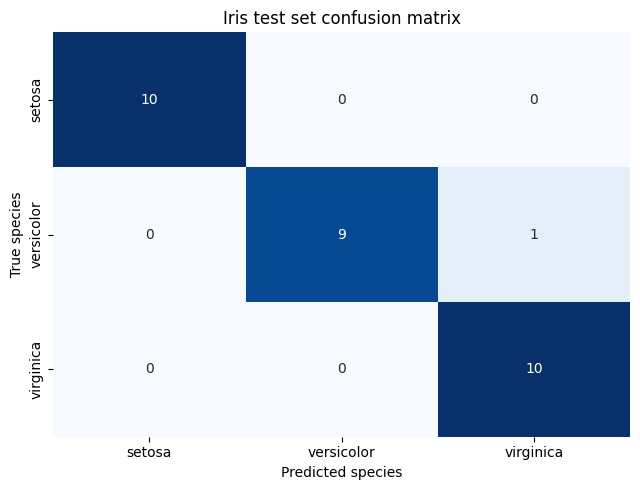

In [6]:
print("Best hyperparameters:", grid_search.best_params_)
print(f"Best mean 5-fold CV accuracy: {grid_search.best_score_:.4f}")
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Held-out test accuracy: {test_accuracy:.4f} ({np.sum(y_pred == y_test)}/{len(y_test)} correct)")
print("\nClassification report (held-out test):")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_names)))
print("Confusion matrix (rows = true species, columns = predicted species):")
print(pd.DataFrame(cm, index=class_names, columns=class_names))
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set(xlabel='Predicted species', ylabel='True species', title='Iris test set confusion matrix')
plt.tight_layout()
plt.show()

# **Questions**

1. **Explain the purpose of hyperparameter tuning.** Why can't we just use the default parameters for a machine learning model, and how does GridSearchCV help automate this process?

2. **What is a machine learning pipeline, and why is it beneficial in this lab?** Specifically, why is it important to include StandardScaler within the pipeline before the classifier, and what problem does this approach solve?

3. **Analyze the results of your grid search. What were the best hyperparameters found by GridSearchCV?** How do these compare to the default values for a Random Forest classifier? Explain why a different combination of parameters might perform better on this specific dataset.

4. **Interpret the final confusion matrix. Based on the matrix, what kind of classification errors did your best model make?** Which of the Iris species was the most difficult for the model to predict correctly, and how can you tell?

## Answers to the lab questions

**1. Purpose of tuning.** Hyperparameters control how a model is built (for example, tree count, depth, and minimum observations for a split). Defaults are general starting points and are not guaranteed to give the highest validation accuracy for this dataset. `GridSearchCV` systematically fits all 36 specified combinations across five training folds, compares their mean validation accuracy, and refits the selected pipeline on the full training partition. The test set is reserved for final assessment.

**2. Why use a pipeline?** A pipeline ties the scaler and classifier into one estimator so each fold learns its scaler only from that fold's training portion. Applying a scaler to the entire dataset before cross-validation would expose validation data to the preprocessing stage (data leakage). Scaling is especially important for distance-based classifiers such as SVM; a Random Forest is based on feature thresholds and is generally insensitive to feature scale. We keep `StandardScaler` because the lab specifies it and it demonstrates safe preprocessing.

**3. Grid search results.** The best values were `n_estimators=50`, `max_depth=None`, and `min_samples_split=10`. The corresponding defaults in this installed scikit-learn are `n_estimators=100`, `max_depth=None`, and `min_samples_split=2`. Best mean 5-fold validation accuracy was **0.9583**; held-out test accuracy was **0.9667** (29/30). Tree count affects ensemble stability, while depth and minimum split size limit complexity; a particular combination may validate better because of the Iris training samples and fold composition. These values are selected from the specified grid; several combinations may tie. The search score alone does not prove the selected values are universally better than defaults.

**4. Confusion matrix.** Each row is the true species and each column is the predicted species. The diagonal gives correct predictions: setosa 10/10, versicolor 9/10, virginica 10/10. Errors: 1 true versicolor predicted as virginica. The lowest diagonal count belongs to versicolor; it was the hardest species on this 30-sample test set.

**Result note.** Test results are based on only ten flowers per species. One additional mistake changes a species recall by 10 percentage points, so avoid treating small differences as definitive.


--------------------------------------------------------------------------------Thank you for your time to review it.-------------------